# Isochrons 01. What is an isochron? FitzHugh-Nagumo, then the reduced Hodgkin-Huxley neuron

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZetaOne/pyauto-xpp/blob/main/isochrons/01_FHN_basics-isochron.ipynb)

An oscillator has a clock: its **phase**. On the limit cycle the phase is easy to read.
This notebook answers one question: *what is the phase of a point that is not on the
limit cycle?* The answer is the **asymptotic phase**, and the curves of equal asymptotic
phase are the **isochrons**.

We build the idea in small steps, by computing everything:

| part | what you will see |
|---|---|
| A. FitzHugh-Nagumo | 1. phase on the cycle · 2. a point off the cycle catches up with one point of the cycle · 3. the phase map and its contour lines, the isochrons · 4. points on one isochron move together · 5. why it matters: kicks and the phase response curve · 6. near the cycle an isochron is a straight line |
| B. Reduced Hodgkin-Huxley | the same steps for the neuron of Osinga & Moehlis; why its isochrons are hard |

Every simulation runs in XPPAUT 8.2 through pyauto-xpp, and each model's `.ode` file is
printed, so you can repeat any step in XPPAUT itself.

Needs: `pip install pyauto-xpp numpy matplotlib tqdm`

Running in Google Colab? This cell installs pyauto-xpp first; elsewhere it does nothing.

In [ ]:
import sys
if "google.colab" in sys.modules:
    %pip -q install pyauto-xpp tqdm --find-links https://github.com/ZetaOne/pyauto-xpp/releases/expanded_assets/v0.3.0

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pyxpp.builder import ModelBuilder
from tqdm.auto import tqdm

WORK = Path(tempfile.mkdtemp())
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})

# Part A. FitzHugh-Nagumo

The FitzHugh-Nagumo model is the simplest model of an excitable neuron, and a relaxation
oscillator like the van der Pol oscillator of Strogatz section 7.5:

$$ \dot v = v - \frac{v^3}{3} - w + I, \qquad \dot w = \varepsilon\,(v + a - b w) $$

v is a fast voltage-like variable, w a slow recovery variable. With a = 0.7, b = 0.8,
ε = 0.08 and I = 0.5 the equilibrium is unstable and every trajectory goes to one stable
limit cycle Γ: the neuron fires periodically.

## A0. The model in XPPAUT

In [2]:
fhn = (ModelBuilder("fhn")
       .ode("v", "v-v^3/3-w+i").ode("w", "eps*(v+a-b*w)")
       .parameter(i=0.5, a=0.7, b=0.8, eps=0.08)
       .initial(v=-1, w=1)
       .option(total=400, dt=0.01, meth="rk4", bound=1e6, maxstor=200000))
print(fhn.render())
m = fhn.load(WORK / "fhn.ode")

v'=v-v^3/3-w+i
w'=eps*(v+a-b*w)
par i=0.5,a=0.7,b=0.8,eps=0.08
init v=-1,w=1
@ total=400,dt=0.01,meth=rungekutta,bound=1000000.0,maxstor=200000
done



## A1. Phase on the cycle

1. Integrate long enough to land on the cycle (XPP: *Initialconds > Go*).
2. *Initialconds > Periodic* finds the period T.
3. Choose phase zero: the point γ0 where v is largest (the top of the spike).
4. A point reached from γ0 after time t has phase θ = t/T, a number in [0, 1).

The phase is a clock that runs at a steady rate 1/T around the cycle.

period T = 39.4744; gamma0 = (1.8521, 0.2343); equilibrium x* = (-0.8048, -0.1311), eigenvalues [0.144+0.191j 0.144-0.191j]


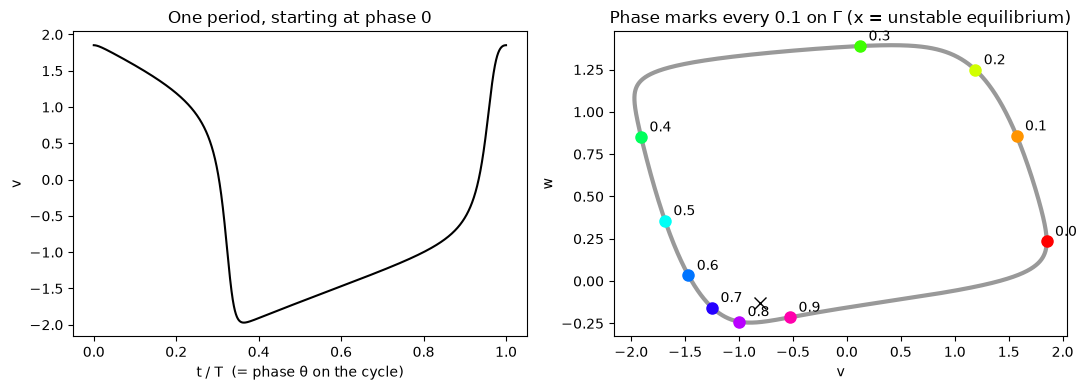

In [3]:
m.run()
m.buttons.xi_vs_t("v")
m.buttons.initialconds.periodic()                 # XPP: Initialconds > Periodic
T = m.numerics["total"]
cyc = m.run(keep=False, total=T, dt=0.001)
k0 = int(np.argmax(cyc["v"]))                      # the top of the spike
gamma0 = np.array([cyc["v"][k0], cyc["w"][k0]])
m.set(v=gamma0[0], w=gamma0[1])
cyc = m.run(keep=False, total=T, dt=0.001)         # one period, starting at phase 0
eq = m.equilibrium({"v": -0.5, "w": 0.0})
xstar = np.array([eq.x["V"], eq.x["W"]])
print(f"period T = {T:.4f}; gamma0 = ({gamma0[0]:.4f}, {gamma0[1]:.4f}); "
      f"equilibrium x* = ({xstar[0]:.4f}, {xstar[1]:.4f}), eigenvalues {np.round(eq.eigenvalues, 3)}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(cyc.t / T, cyc["v"], color="k")
a1.set(xlabel="t / T  (= phase θ on the cycle)", ylabel="v", title="One period, starting at phase 0")
a2.plot(cyc["v"], cyc["w"], color="0.6", lw=3)
for th in np.arange(0, 1, 0.1):
    j = int(th * (len(cyc.t) - 1))
    a2.plot(cyc["v"][j], cyc["w"][j], "o", color=plt.cm.hsv(th), ms=8)
    a2.annotate(f"{th:.1f}", (cyc["v"][j], cyc["w"][j]), xytext=(6, 4), textcoords="offset points")
a2.plot(*xstar, "x", color="k", ms=9)
a2.set(xlabel="v", ylabel="w", title="Phase marks every 0.1 on Γ (x = unstable equilibrium)")
plt.tight_layout(); plt.show()

The marks are crowded where the cycle moves slowly (the slow branches) and far apart on
the fast jumps: equal steps in phase are equal steps in **time**, not in distance.

## A2. A point off the cycle catches up with one point of the cycle

Take a point x0 that is **not** on Γ and integrate it. It converges to Γ, but where on Γ?
Compare it with a point that moves around Γ. After the transient, the trajectory from
x0 becomes indistinguishable from the trajectory of one particular point of Γ. That
point's phase is the **asymptotic phase** θ(x0) of x0:

$$ \lim_{t\to\infty} \big\| \Phi(t, x_0) - \Phi(t + \theta(x_0)\,T,\ \gamma_0) \big\| = 0 $$

How to measure it: wait until x0 has settled, note the time t_s of one of its spikes
(v crossing 0 upward), and compare with the spike of the cycle that starts at γ0 at time
t_c0. If x0 spikes earlier by a time Δ, it is ahead by Δ/T of a cycle:

$$ \theta(x_0) = \frac{t_{c0} - t_s}{T} \mod 1 $$

cycle spikes at t_c0 = 36.848 after gamma0; x0 spikes at t_s = 221.770
asymptotic phase of x0 = ((t_c0 - t_s)/T) mod 1 = 0.3154


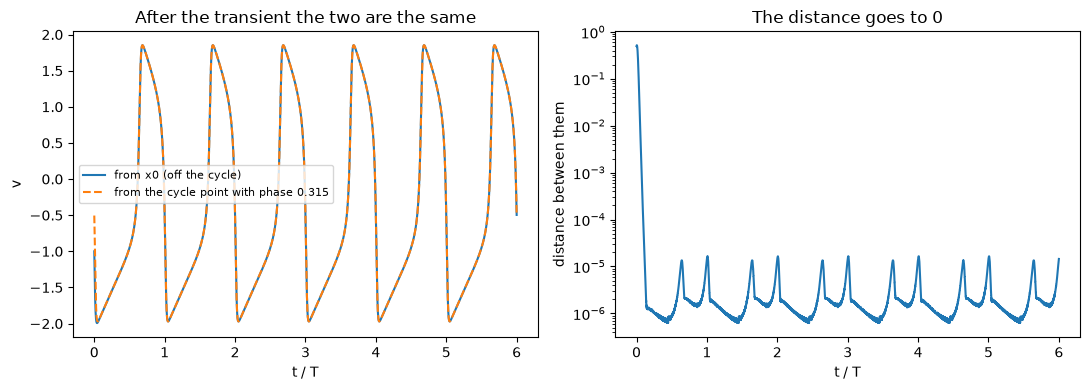

In [4]:
def upcross(t, v, thr=0.0):
    """times where v crosses thr upward (linear interpolation)"""
    i = np.nonzero((v[:-1] < thr) & (v[1:] >= thr))[0]
    return t[i] + (thr - v[i]) / (v[i + 1] - v[i]) * (t[i + 1] - t[i])


m.set(v=gamma0[0], w=gamma0[1])
ref = m.run(keep=False, total=6 * T, dt=0.01)
tc0 = upcross(ref.t, ref["v"])[0]                  # the cycle's first spike after gamma0
x0 = np.array([-1.0, 1.4])                         # a point off the cycle
m.set(v=x0[0], w=x0[1])
tr = m.run(keep=False, total=6 * T, dt=0.01)
ts = upcross(tr.t, tr["v"])[-1]                    # a spike after settling
theta_x0 = ((tc0 - ts) / T) % 1
print(f"cycle spikes at t_c0 = {tc0:.3f} after gamma0; x0 spikes at t_s = {ts:.3f}")
print(f"asymptotic phase of x0 = ((t_c0 - t_s)/T) mod 1 = {theta_x0:.4f}")

# the point of the cycle with that phase, followed together with x0
g_th = np.array([np.interp(theta_x0 * T, cyc.t, cyc["v"]), np.interp(theta_x0 * T, cyc.t, cyc["w"])])
m.set(v=g_th[0], w=g_th[1])
tr2 = m.run(keep=False, total=6 * T, dt=0.01)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(tr.t / T, tr["v"], label="from x0 (off the cycle)")
a1.plot(tr2.t / T, tr2["v"], "--", label=f"from the cycle point with phase {theta_x0:.3f}")
a1.set(xlabel="t / T", ylabel="v", title="After the transient the two are the same")
a1.legend(fontsize=8)
a2.semilogy(tr.t / T, np.hypot(tr["v"] - tr2["v"], tr["w"] - tr2["w"]))
a2.set(xlabel="t / T", ylabel="distance between them", title="The distance goes to 0")
plt.tight_layout(); plt.show()

## A3. The phase map, and the isochrons as its contour lines

Do the same for every point of a grid: the asymptotic phase becomes a function θ(v, w)
on the plane. The **isochron** of a point γ on Γ is the set of all points with the same
asymptotic phase as γ, i.e. a contour line of θ. Points on one isochron end up moving
together, in step with γ.

To be fast, many points are integrated in one XPP run: an XPP *network* of N identical,
uncoupled copies of the model (`v[0..N-1]`, `w[0..N-1]`). Its `.ode` file:

In [5]:
NC = 200                                           # copies per XPP run


def network(name, fun, rhs, pars, opts):
    """N uncoupled copies of a 2-variable model as one XPP model; rhs = {var: expr} in terms of the
    single-copy variables, which are rewritten to their indexed form var[j]"""
    nb = ModelBuilder(name)
    for sig, expr in fun:
        nb.function(sig, expr)
    names = list(rhs)
    for var, expr in rhs.items():
        e = expr
        for other in names:                         # v -> v[j], w -> w[j] (whole words only)
            e = __import__("re").sub(rf"\b{other}\b", f"{other}[j]", e)
        nb.ode(f"{var}[0..{NC - 1}]", e)
    return nb.parameter(**pars).option(maxstor=400000, **opts).load(WORK / f"{name}.ode")


FHN_RHS = {"v": "v-v^3/3-w+i", "w": "eps*(v+a-b*w)"}
net_fhn = network("fhn_net", [], FHN_RHS, dict(i=0.5, a=0.7, b=0.8, eps=0.08),
                  dict(meth="rk4", dt=0.01, bound=1e6))
print("\n".join(net_fhn.path.read_text().splitlines()[:4]), "\n...")


def phase_of(net, pts, T, tc0, var=("v", "w"), thr=0.0, nper=8, dt=0.01):
    """asymptotic phase of each point (NaN if it has not settled after nper periods)"""
    pts = np.asarray(pts, float)
    out = np.full(len(pts), np.nan)
    net.numerics.update(dt=dt)
    for i0 in range(0, len(pts), NC):
        chunk = pts[i0:i0 + NC]
        ic = {}
        for j in range(NC):
            x = chunk[j] if j < len(chunk) else chunk[0]
            ic[f"{var[0]}{j}"], ic[f"{var[1]}{j}"] = x[0], x[1]
        net.ics.update(ic)
        A = net.run(total=nper * T, trans=(nper - 2.5) * T).array
        t, V = A[:, 0], A[:, 1:1 + len(chunk)]
        for c in range(len(chunk)):
            s = upcross(t, V[:, c], thr)
            if len(s) >= 2 and abs(s[-1] - s[-2] - T) < 1e-3 * T:     # settled: spikes one period apart
                out[i0 + c] = ((tc0 - s[-1]) / T) % 1
    return out


vg, wg = np.linspace(-2.5, 2.5, 81), np.linspace(-1.0, 2.0, 61)
VG, WG = np.meshgrid(vg, wg)
grid = np.c_[VG.ravel(), WG.ravel()]
TH = np.concatenate([phase_of(net_fhn, grid[i:i + 1000], T, tc0)
                     for i in tqdm(range(0, len(grid), 1000), desc="FHN phase map")]).reshape(VG.shape)
print(f"{np.isnan(TH).sum()} of {TH.size} grid points did not settle (they start very near x*)")
# (the map is drawn as an animation below; it is also used in A4 and A6)


def no_wrap(F):
    """F with the grid points next to a jump of more than 0.5 masked: there the phase wraps
    from 1 to 0 (or crosses a strip too thin for the grid), and a contour drawn through the
    jump would be a false line"""
    bad = np.zeros(F.shape, bool)
    dx = np.abs(np.diff(F, axis=1)) > 0.5
    dy = np.abs(np.diff(F, axis=0)) > 0.5
    bad[:, :-1] |= dx; bad[:, 1:] |= dx; bad[:-1, :] |= dy; bad[1:, :] |= dy
    return np.ma.masked_where(bad | np.isnan(F), F)


def draw_isochrons(ax, X, Y, TH, levels=np.arange(0.05, 1, 0.1), **kw):
    """contour lines of the phase. Levels near 0/1 are drawn from the phase shifted by half a
    cycle, and grid cells at a jump are left out (no_wrap), so no false lines appear"""
    S = (TH + 0.5) % 1
    lo = [l for l in levels if 0.25 <= l <= 0.75]
    hi = [(l + 0.5) % 1 for l in levels if not 0.25 <= l <= 0.75]
    ax.contour(X, Y, no_wrap(TH), lo, **kw)
    ax.contour(X, Y, no_wrap(S), sorted(hi), **kw)

v[0..199]'=v[j]-v[j]^3/3-w[j]+i
w[0..199]'=eps*(v[j]+a-b*w[j])
par i=0.5,a=0.7,b=0.8,eps=0.08
@ maxstor=400000,meth=rungekutta,dt=0.01,bound=1000000.0 
...


FHN phase map:   0%|          | 0/5 [00:00<?, ?it/s]

0 of 4941 grid points did not settle (they start very near x*)


**The phase map as an animation** (made by `make_isochron_gifs.py` from the same kind of map,
on a finer grid). Left: the colour is the asymptotic phase, the thin lines are isochrons, and
the thick line is the isochron of the white point as it goes around the cycle: it sweeps the
plane once per period, like the hand of a clock. Right: grid points coloured by their
asymptotic phase, all integrated together; each colour lands on its own point of the cycle.

![FHN: the isochron of the moving point sweeps the plane](https://raw.githubusercontent.com/ZetaOne/pyauto-xpp/main/isochrons/gifs/fhn_isochron_sweep.gif) ![FHN: points coloured by asymptotic phase flow onto the cycle](https://raw.githubusercontent.com/ZetaOne/pyauto-xpp/main/isochrons/gifs/fhn_flow.gif)

What to see:
* Each isochron crosses the cycle **once**, at the point with that phase, and runs on
  both sides of it.
* Inside the cycle all isochrons converge on the unstable equilibrium x*: it has no
  asymptotic phase (it never reaches the cycle). This is the **phaseless set**.
* Isochrons are bunched where the phase changes quickly with position, spread out where
  it changes slowly.

## A4. Points on one isochron move together

Take all grid points with phase ≈ 0.25 (one isochron), and integrate them. At every time
they lie on one isochron again (of phase 0.25 + t/T), and they all converge onto the
**same** moving point of the cycle. That is what "same asymptotic phase" means.

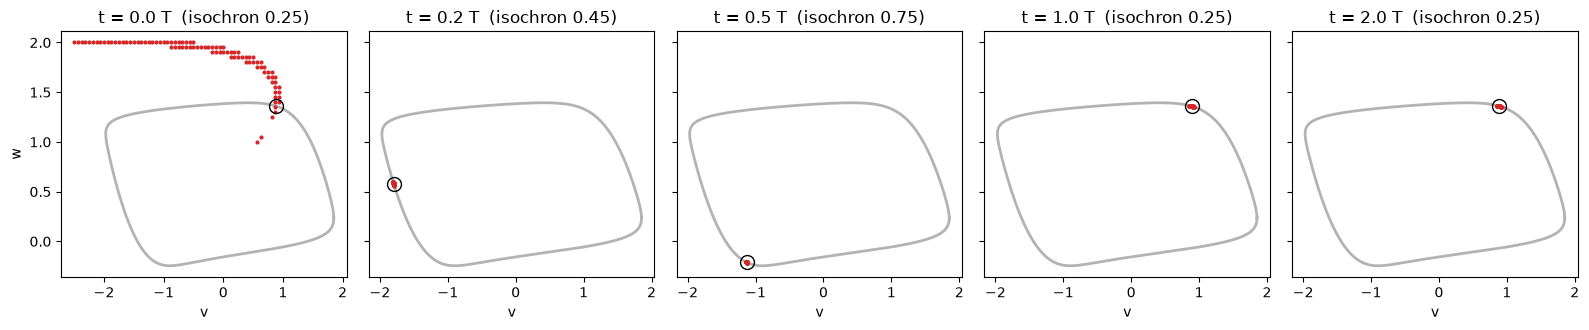

In [6]:
sel = grid[np.abs(TH.ravel() - 0.25) < 0.004]
times = [0, 0.2 * T, 0.5 * T, T, 2 * T]
snap = []
net_fhn.numerics.update(dt=0.01)
ic = {}
for j in range(NC):
    x = sel[j] if j < len(sel) else sel[0]
    ic[f"v{j}"], ic[f"w{j}"] = x[0], x[1]
net_fhn.ics.update(ic)
A = net_fhn.run(total=2 * T, trans=0).array
fig, axs = plt.subplots(1, len(times), figsize=(16, 3.4), sharey=True)
for ax, tt in zip(axs, times):
    k = int(np.argmin(np.abs(A[:, 0] - tt)))
    ax.plot(cyc["v"], cyc["w"], color="0.7", lw=2)
    ax.plot(A[k, 1:1 + len(sel[:NC])], A[k, 1 + NC:1 + NC + len(sel[:NC])], ".", color="C3", ms=4)
    th_now = (0.25 + tt / T) % 1
    j = int(th_now * (len(cyc.t) - 1))
    ax.plot(cyc["v"][j], cyc["w"][j], "o", mfc="none", mec="k", ms=10)
    ax.set(title=f"t = {tt / T:.1f} T  (isochron {th_now:.2f})", xlabel="v")
axs[0].set_ylabel("w")
plt.tight_layout(); plt.show()

The red points start spread along the isochron of phase 0.25. As time goes on they stay
on one curve, which is an isochron again (the flow carries isochrons onto isochrons),
and they shrink onto the circled point of the cycle, which has moved on by t/T.

## A5. Why it matters: a kick and the phase response curve

A brief input (a current pulse) moves the state instantly, here by Δv. The state jumps
from one isochron to another, and the difference of the two phases is the **phase
shift** the kick causes: the oscillator now runs ahead or behind. Plotting the phase
shift against the phase at which the kick arrives gives the **phase response curve
(PRC)**, the basic object of phase models of coupled and forced oscillators.

Below: the PRC for kicks Δv = 0.1 and 0.5, measured with the phase function of A2, and
the infinitesimal PRC from XPP's adjoint (*Numerics > Averaging > New adj*), which is
the limit of small kicks: Δθ ≈ Z_v(θ) Δv / T.

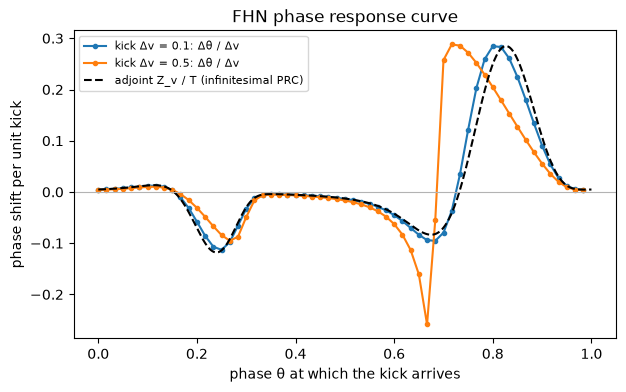

In [7]:
ths = np.linspace(0, 1, 60, endpoint=False)
on_cycle = np.c_[np.interp(ths * T, cyc.t, cyc["v"]), np.interp(ths * T, cyc.t, cyc["w"])]
m.set(v=gamma0[0], w=gamma0[1])
m.run(keep=False, total=T, dt=0.001)
A_ = m.buttons.numerics.averaging
A_.parameters(2000)
A_.new_adj()                                       # XPP: Numerics > Averaging > New adj
adj = m.data
fig, ax = plt.subplots(figsize=(7, 4))
for dv in (0.1, 0.5):
    th_new = phase_of(net_fhn, on_cycle + [dv, 0], T, tc0)
    dth = (th_new - ths + 0.5) % 1 - 0.5
    ax.plot(ths, dth / dv, "o-", ms=3, label=f"kick Δv = {dv}: Δθ / Δv")
ax.plot(adj.t / T, adj["v"] / T, "k--", label="adjoint Z_v / T (infinitesimal PRC)")
ax.axhline(0, color="0.7", lw=0.8)
ax.set(xlabel="phase θ at which the kick arrives", ylabel="phase shift per unit kick",
       title="FHN phase response curve")
ax.legend(fontsize=8)
plt.show()

Small kicks follow the adjoint curve; a large kick lands on an isochron far from the
cycle, where the isochrons bend, and the response deviates. **To know the effect of
large kicks you need the isochrons far from the cycle: global isochrons.** That is what
Osinga & Moehlis compute.

## A6. Near the cycle, an isochron is a straight line

Close to γ, the isochron I(γ) is almost a straight segment. Its direction n_s is
perpendicular to the adjoint vector Z (the gradient of the phase). Below: the isochron
θ = 0.25 from the phase map, and the straight line through γ(0.25) perpendicular to Z.
This straight piece, of half-length η, is where the continuation method starts (stage 02).

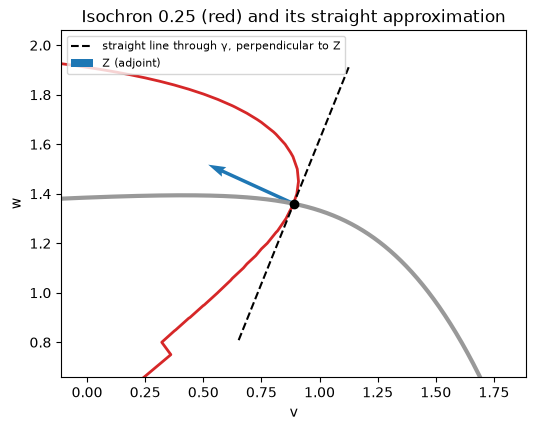

In [8]:
th0 = 0.25
g = np.array([np.interp(th0 * T, cyc.t, cyc["v"]), np.interp(th0 * T, cyc.t, cyc["w"])])
Z = np.array([np.interp(th0 * T, adj.t, adj["v"]), np.interp(th0 * T, adj.t, adj["w"])])
ns = np.array([Z[1], -Z[0]]) / np.hypot(*Z)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.contour(VG, WG, TH, [th0], colors="C3", linewidths=2)
ax.plot(cyc["v"], cyc["w"], color="0.6", lw=3)
s = np.linspace(-0.6, 0.6, 2)
ax.plot(g[0] + s * ns[0], g[1] + s * ns[1], "k--", label="straight line through γ, perpendicular to Z")
ax.quiver(*g, *(Z / np.hypot(*Z) * 0.4), color="C0", angles="xy", scale_units="xy", scale=1, label="Z (adjoint)")
ax.plot(*g, "ko")
ax.set(xlim=(g[0] - 1, g[0] + 1), ylim=(g[1] - 0.7, g[1] + 0.7), xlabel="v", ylabel="w",
       title="Isochron 0.25 (red) and its straight approximation")
ax.legend(fontsize=8)
plt.show()

# Part B. The reduced Hodgkin-Huxley model

Now the same steps for the model of Osinga & Moehlis: voltage V and potassium gate n
(the paper's eq. 4.1). It is also a relaxation oscillator, but with a much stronger
separation of time scales than FHN. The `.ode` file:

In [9]:
FUN = [("am(v)", "0.1*(v+40)/(1-exp(-(v+40)/10))"), ("bm(v)", "4*exp(-(v+65)/18)"),
       ("an(v)", "0.01*(v+55)/(1-exp(-(v+55)/10))"), ("bn(v)", "0.125*exp(-(v+65)/80)"),
       ("minf(v)", "am(v)/(am(v)+bm(v))")]
HH_RHS = {"v": "iapp-gna*minf(v)^3*(0.8-n)*(v-ena)-gk*n^4*(v-ek)-gl*(v-el)",
          "n": "an(v)*(1-n)-bn(v)*n"}
HH_PARS = dict(iapp=10, gna=120, gk=36, gl=0.3, ena=50, ek=-77, el=-54.4)
hb = ModelBuilder("reduced_hh")
for sig, expr in FUN:
    hb.function(sig, expr)
hb = (hb.ode("v", HH_RHS["v"]).ode("n", HH_RHS["n"]).parameter(**HH_PARS).initial(v=-60, n=0.3)
      .option(total=300, dt=0.01, meth="rk4", bound=1e6, maxstor=200000))
print(hb.render())
h = hb.load(WORK / "reduced_hh.ode")

am(v)=0.1*(v+40)/(1-exp(-(v+40)/10))
bm(v)=4*exp(-(v+65)/18)
an(v)=0.01*(v+55)/(1-exp(-(v+55)/10))
bn(v)=0.125*exp(-(v+65)/80)
minf(v)=am(v)/(am(v)+bm(v))
v'=iapp-gna*minf(v)^3*(0.8-n)*(v-ena)-gk*n^4*(v-ek)-gl*(v-el)
n'=an(v)*(1-n)-bn(v)*n
par iapp=10,gna=120,gk=36,gl=0.3,ena=50,ek=-77,el=-54.4
init v=-60,n=0.3
@ total=300,dt=0.01,meth=rungekutta,bound=1000000.0,maxstor=200000
done



## B1. Phase on the cycle

T = 11.8463 (paper 11.8463); gamma0 = (44.706, 0.4597); x* = (-59.604, 0.4026)


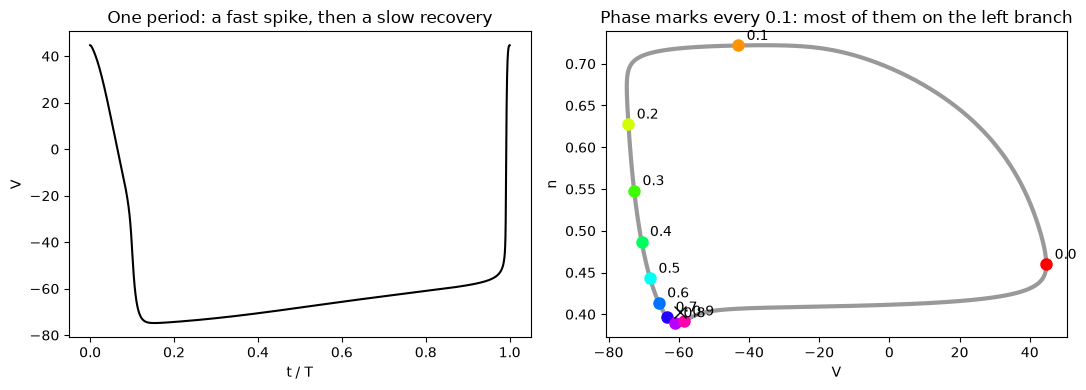

In [10]:
h.run()
h.buttons.xi_vs_t("v")
h.buttons.initialconds.periodic()
Th = h.numerics["total"]
hc = h.run(keep=False, total=Th, dt=0.001)
k0 = int(np.argmax(hc["v"]))
g0h = np.array([hc["v"][k0], hc["n"][k0]])
h.set(v=g0h[0], n=g0h[1])
hc = h.run(keep=False, total=Th, dt=0.001)
eqh = h.equilibrium({"v": -60, "n": 0.4})
xh = np.array([eqh.x["V"], eqh.x["N"]])
print(f"T = {Th:.4f} (paper 11.8463); gamma0 = ({g0h[0]:.3f}, {g0h[1]:.4f}); x* = ({xh[0]:.3f}, {xh[1]:.4f})")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(hc.t / Th, hc["v"], color="k")
a1.set(xlabel="t / T", ylabel="V", title="One period: a fast spike, then a slow recovery")
a2.plot(hc["v"], hc["n"], color="0.6", lw=3)
for th in np.arange(0, 1, 0.1):
    j = int(th * (len(hc.t) - 1))
    a2.plot(hc["v"][j], hc["n"][j], "o", color=plt.cm.hsv(th), ms=8)
    a2.annotate(f"{th:.1f}", (hc["v"][j], hc["n"][j]), xytext=(6, 4), textcoords="offset points")
a2.plot(*xh, "x", color="k", ms=9)
a2.set(xlabel="V", ylabel="n", title="Phase marks every 0.1: most of them on the left branch")
plt.tight_layout(); plt.show()

Phases 0.1 to 0.9 are almost all on the slow left branch: the spike (the right half of
the picture) takes only about a tenth of the period.

## B2–B3. The phase map and the isochrons

Same method as A3 (a network of copies, phase from spike times with V crossing −20).

In [11]:
net_hh = network("hh_net", FUN, HH_RHS, HH_PARS, dict(meth="rk4", dt=0.01, bound=1e6))
h.set(v=g0h[0], n=g0h[1])
r = h.run(keep=False, total=3 * Th, dt=0.01)
tc0h = upcross(r.t, r["v"], -20)[0]
vh, nh = np.linspace(-90, 52, 101), np.linspace(0.3, 0.8, 81)
VH, NH = np.meshgrid(vh, nh)
gh = np.c_[VH.ravel(), NH.ravel()]
THH = np.concatenate([phase_of(net_hh, gh[i:i + 1000], Th, tc0h, var=("v", "n"), thr=-20)
                      for i in tqdm(range(0, len(gh), 1000), desc="reduced HH phase map")]).reshape(VH.shape)

reduced HH phase map:   0%|          | 0/9 [00:00<?, ?it/s]

**The reduced HH phase map as an animation** (from `make_isochron_gifs.py`): the sweeping
isochron of the moving point, and grid points coloured by asymptotic phase flowing onto the
cycle.

![Reduced HH: the isochron of the moving point sweeps the plane](https://raw.githubusercontent.com/ZetaOne/pyauto-xpp/main/isochrons/gifs/hh_isochron_sweep.gif) ![Reduced HH: points coloured by asymptotic phase flow onto the cycle](https://raw.githubusercontent.com/ZetaOne/pyauto-xpp/main/isochrons/gifs/hh_flow.gif)

Compare with FHN:
* Outside the cycle the isochrons are almost **horizontal**: far from Γ the fast V
  motion dominates, so the phase is set mostly by n.
* Inside the cycle the phase map is split by a sharp boundary along the middle branch of
  the V-nullcline: just left of it the phase is about 0.3, just right of it about 0.
  **All the other phases are squeezed into this thin strip**, thinner than any grid can
  resolve. Points on either side of the strip either jump left or fire a spike.

## B4. Why this is hard

Zoom into the strip: the phase jumps from one value to another across a tiny distance.

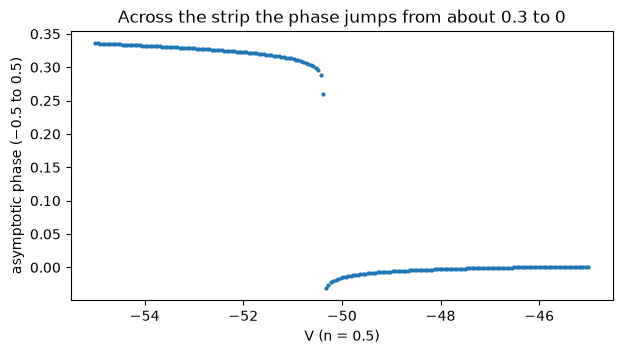

In [12]:
Vline = np.linspace(-55, -45, 200)
pts = np.c_[Vline, np.full_like(Vline, 0.5)]
th_line = phase_of(net_hh, pts, Th, tc0h, var=("v", "n"), thr=-20)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(Vline, (th_line + 0.5) % 1 - 0.5, ".", ms=4)   # phase shown in [-0.5, 0.5): 0.99 is -0.01
ax.set(xlabel="V (n = 0.5)", ylabel="asymptotic phase (−0.5 to 0.5)",
       title="Across the strip the phase jumps from about 0.3 to 0")
plt.show()

Even with 200 points over 10 mV the phase jumps from about 0.3 to about 0 between two
neighbouring points (near V = −50.4). Making the grid finer does not help: the strip is exponentially
thin, so the isochrons inside it cannot be drawn from a phase map, and they cannot be
drawn by integrating backward either (the backward flow stretches distances by about
10^20 per period). Seeing them needs a different method: the **continuation of orbit
segments** of Osinga & Moehlis, which is stage 02.

## Summary

* **Phase on the cycle**: θ = t/T, a clock.
* **Asymptotic phase** of any point: the phase of the cycle point it ends up in step
  with; measured by comparing spike times after the transient.
* **Isochron** I(γ): all points with γ's asymptotic phase; the contour lines of the
  phase map. Points on one isochron move together and converge onto one moving point.
* **Phaseless set**: points that never reach the cycle (the unstable equilibrium);
  every isochron ends there.
* **Why**: a kick moves the state across isochrons; the phase response curve is read
  off them. Near the cycle they are straight lines ⟂ the adjoint.
* **Reduced HH**: all phases are packed into a thin strip along the repelling middle
  branch; brute force cannot resolve it, so stage 02 uses continuation.